# Laboratorio de regresión logística

|                |   |
:----------------|---|
| **Nombre**     | Juan Pablo Moran |
| **Fecha**      | 12/10/2026 |
| **Expediente** | 753760 |

In machine learning, Support Vector Machines (SVM) are supervised learning models with associated learning algorithms that analyze data used for classification and regression analysis. It is mostly used in classification problems. In this algorithm, each data item is plotted as a point in p-dimensional space (where p is the number of features), with the value of each feature being the value of a particular coordinate. Then, classification is performed by finding the hyper-plane that best differentiates the two classes (or more if we have a multi class problem):

$$ f(x) = w^T \varphi(x) + b $$

where $\varphi: X \rightarrow F $ is a function that makes each input point $x$ correspond to a point in F, where F is a Hilbert space.

In addition to performing linear classification, SVMs can efficiently perform a non-linear classification, implicitly mapping their inputs into high-dimensional feature spaces (more specifically using the kernel trick, like the RBF funcion). 

[1]

OLS utilizes the squared residuals to fit the parameters. Large residuals caused by outliers may worsen the accuracy significantly.

Support Vectors use piecewise linear functions to counter this, in which a hyperparameter  $\epsilon$ called the margin lets errors that are less or equal to it be 0, and error larger than it be $e - \epsilon$. 

The problem to solve is:

\begin{split}
        \min_{w, b, \xi, \xi^*} \mathcal{P}_\epsilon(w, b, \xi) &= \frac{1}{2} w^T w + c \sum_{k=1}^{N} \xi_k \\
        \text{s.t. } & y_k [w^T \varphi(x_k) - b] \geq 1- \xi_k,\ \ k = 1, ..., N \\
        & \xi_k \geq 0,\ \ k = 1, ..., N
\end{split}


The most important question that arises when using a SVM is how to choose the correct hyperplane. Consider the following scenarios:

### Scenario 1

In this scenario there are three hyperplanes called A, B, and C. Now, the problem is to identify the hyperplane which best differentiates the stars and the circles.

<center><img src="https://media.geeksforgeeks.org/wp-content/uploads/SVM_21-2.png" alt="what image shows"></center>

In this case, hyperplane B separates the stars and the circle betters, hence it is the correct hyperplane.


### Scenario 2

Now take another scenario where all three hyperplanes are segregating classes well. The question that arises is how to choose the best hyperplane in this situation.

<center><img src="https://media.geeksforgeeks.org/wp-content/uploads/SVM_4-2.png" alt="what image shows"></center>

In such scenarios, we calculate the margin (which is the distance between nearest data point and the hyperplane). The hyperplane with the largest margin will be considered as the correct hyperplane to classify the dataset.

Here C has the largest margin. Hence, it is considered as the best hyperplane.


### Kernels
Knowing 
$$ w = \sum_{k=1}^{N} \alpha_k y_k \varphi(x_k) $$

And
$$ y_{pred} = w^T \varphi(x) + b $$

Then 
$$ y_{pred} = (\sum_{k=1}^{N} \alpha_k y_k \varphi(x_k))^T \varphi(x) + b $$

Where $\varphi$ is a function that makes each input in $x$ correspond to a point in $F$ (a Hilbert space). This can be seen as processing and transforming the input featuers to keep the model's convexity. [2]

This also allows us to transform the inputs into another space where they might be more easily classified.

<center><img src=https://miro.medium.com/max/838/1*gXvhD4IomaC9Jb37tzDUVg.png alt="what image shows"></center>

## ROC and AUC

A ROC (Receiver Operating Characteristic) is a graph that shows how the classification model performs at the classification thresholds. 

ROC curves typically feature true positive rate on the Y axis, and false positive rate on the X axis. This means that the top left corner of the plot is the “ideal” point - a false positive rate of zero, and a true positive rate of one. This is not very realistic, but it does mean that a larger area under the curve (AUC) is usually better. [3]

True Positive Rate is a synonym for Recall and defined as:
$$ TPR = \frac{TP}{TP + FN} $$

False Positive Rate is a synonym for Specificity and defined as:

$$ FPR = \frac{FP}{FP + TN} $$

ROC curves are typically used in binary classification to study the output of a classifier. In order to extend ROC curve and ROC area to multi-label classification, it is necessary to binarize the output. One ROC curve can be drawn per label, but one can also draw a ROC curve by considering each element of the label indicator matrix as a binary prediction (micro-averaging).

E.g. If you lower a classification threshold, more items would be classified as positive, increasing False Positives and True Positives.

AUC stands for Area under the ROC.

## Ejercicio 1

- Utiliza el dataset `Iris`, modela con SVC y haz Cross-Validation de diferentes kernels ('linear', 'poly', 'rbf', 'sigmoid').
- Modela con LogisticRegression.
- El método de Cross-Validation es K-Folds con $k=10$.
- Utiliza el AUC como métrico de Cross-Validation.
- Compara resultados.

In [1]:
from sklearn import datasets
import pandas as pd
import numpy as np

iris = datasets.load_iris()
X = iris.data
y = iris.target
print(iris.feature_names)
print(iris.target_names)
print(X.shape)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']
(150, 4)


- Iris tiene 150 flores, 4 factores (largo y ancho de sepalo y petalo) y 3 clases (setosa, versicolor, virginica)
- Como son 3 clases se usa `roc_auc_ovr` (one vs rest): calcula un AUC por clase contra las demas y los promedia
- Con `cv=10`, `cross_val_score` hace K-Folds con k = 10; para clasificacion los folds son estratificados, o sea cada fold trae flores de las 3 clases (los datos de Iris vienen ordenados por clase, si no fuera asi habria folds con una sola clase y no se podria calcular el AUC)
- Para `roc_auc_ovr` el SVC necesita `probability=True` para poder dar probabilidades

In [2]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

kernels = ["linear", "poly", "rbf", "sigmoid"]
modelos = []
auc_media = []
auc_std = []

for k in kernels:
    svc = SVC(kernel=k, probability=True, random_state=0)
    auc = cross_val_score(svc, X, y, cv=10, scoring="roc_auc_ovr")
    modelos.append("SVC " + k)
    auc_media.append(auc.mean())
    auc_std.append(np.std(auc))

lr = LogisticRegression()
auc = cross_val_score(lr, X, y, cv=10, scoring="roc_auc_ovr")
modelos.append("LogisticRegression")
auc_media.append(auc.mean())
auc_std.append(np.std(auc))

resultados_iris = pd.DataFrame({"AUC media": auc_media, "AUC std": auc_std}, index=modelos)
resultados_iris

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

,AUC media,AUC std
SVC linear,0.998667,0.004000
SVC poly,0.998667,0.004000
SVC rbf,0.997333,0.005333
SVC sigmoid,0.750000,0.055797
LogisticRegression,0.998667,0.004000


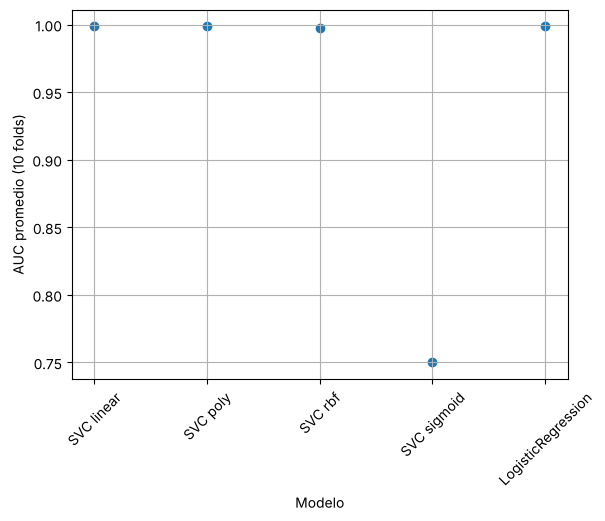

In [3]:
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(modelos, auc_media)
plt.xlabel("Modelo")
plt.ylabel("AUC promedio (10 folds)")
plt.xticks(rotation=45)
plt.grid()

- SVC lineal, polinomial y la regresion logistica empatan con AUC de 0.9987, practicamente perfecto
- RBF queda casi igual (0.9973)
- El kernel sigmoide es el peor por mucho (AUC de 0.75) y tambien el que mas varia entre folds
- Iris es un dataset muy facil de separar, por eso casi todos los modelos funcionan; no hace falta un kernel complicado, con uno lineal o con regresion logistica es suficiente

## Ejercicio 2
- Repite el ejercicio 1 con el dataset `Default`. Utiliza `default` como target.

In [4]:
data = pd.read_csv("Default.csv")
data.head()

,default,student,balance,income
0,No,No,729.526495,44361.625074
1,No,Yes,817.180407,12106.134700
2,No,No,1073.549164,31767.138947
3,No,No,529.250605,35704.493935
4,No,No,785.655883,38463.495879


- `default` es el target, se convierte a verdadero / falso como en el Lab C1
- `student` se convierte a 1 y 0
- `balance` e `income` estan en escalas muy distintas (cientos vs decenas de miles). La SVM usa distancias, asi que se estandarizan (z-score) como en la practica de escalamiento

In [5]:
n = len(data)

balance_media = np.sum(data["balance"]) / n
balance_std = np.sqrt(np.sum((data["balance"] - balance_media)**2) / n)
data["balance_z"] = (data["balance"] - balance_media) / balance_std

income_media = np.sum(data["income"]) / n
income_std = np.sqrt(np.sum((data["income"] - income_media)**2) / n)
data["income_z"] = (data["income"] - income_media) / income_std

data["student_n"] = (data["student"] == "Yes").astype(int)

X2 = data[["balance_z", "income_z", "student_n"]]
y2 = data["default"] == "Yes"
X2.describe()

,balance_z,income_z,student_n
count,1.000000e+04,1.000000e+04,10000.000000
mean,-1.094236e-16,3.272049e-16,0.294400
std,1.000050e+00,1.000050e+00,0.455795
min,-1.727085e+00,-2.455390e+00,0.000000
25%,-7.311361e-01,-9.130582e-01,0.000000
50%,-2.426739e-02,7.765935e-02,0.000000
75%,6.841840e-01,7.716533e-01,1.000000
max,3.760559e+00,3.002200e+00,1.000000


In [6]:
modelos2 = []
auc_media2 = []
auc_std2 = []

for k in kernels:
    svc = SVC(kernel=k)
    auc = cross_val_score(svc, X2, y2, cv=10, scoring="roc_auc")
    modelos2.append("SVC " + k)
    auc_media2.append(auc.mean())
    auc_std2.append(np.std(auc))

lr = LogisticRegression()
auc = cross_val_score(lr, X2, y2, cv=10, scoring="roc_auc")
modelos2.append("LogisticRegression")
auc_media2.append(auc.mean())
auc_std2.append(np.std(auc))

resultados_default = pd.DataFrame({"AUC media": auc_media2, "AUC std": auc_std2}, index=modelos2)
resultados_default

,AUC media,AUC std
SVC linear,0.922296,0.038257
SVC poly,0.892730,0.017627
SVC rbf,0.776361,0.032550
SVC sigmoid,0.798242,0.042724
LogisticRegression,0.949837,0.013355


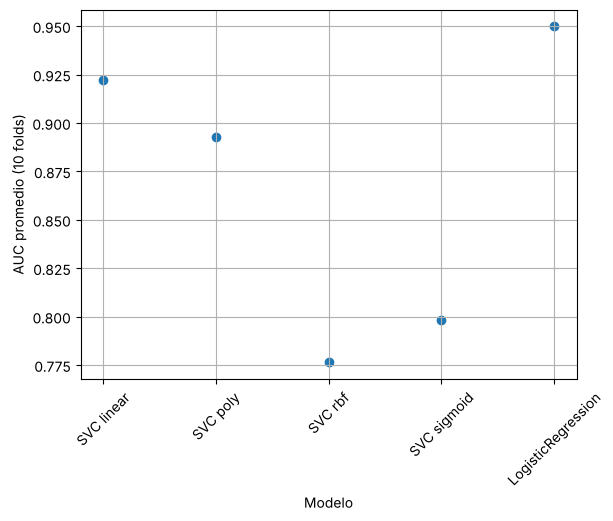

In [7]:
plt.figure()
plt.scatter(modelos2, auc_media2)
plt.xlabel("Modelo")
plt.ylabel("AUC promedio (10 folds)")
plt.xticks(rotation=45)
plt.grid()

- Aqui el target es binario, entonces se usa `roc_auc` normal
- El mejor modelo es la regresion logistica (AUC de 0.95) y ademas es el mas estable entre folds (std mas chica)
- Despues va el SVC lineal (0.92) y el polinomial (0.89)
- RBF (0.78) y sigmoide (0.80) son los peores
- Tiene sentido porque en el Lab C1 vimos que el default depende casi solo del balance y de forma monotona (mas balance, mas probabilidad), entonces una frontera lineal es suficiente y los kernels mas flexibles no ayudan
- Ademas solo 333 de 10,000 personas hicieron default; con clases tan desbalanceadas la regresion logistica, que da probabilidades, ordena mejor a las personas que la SVM

**Comparacion de los dos ejercicios**
- En Iris todos los modelos menos el sigmoide son casi perfectos porque las clases se separan facilmente
- En Default si hay diferencias: los modelos lineales (logistica y SVC lineal) le ganan a los kernels no lineales
- En los dos casos el kernel sigmoide sale mal; un modelo mas complejo no siempre es mejor

# Addendum

Métricos disponibles para clasificación:
- ‘accuracy’
- ‘balanced_accuracy’
- ‘top_k_accuracy’
- ‘average_precision’
- ‘neg_brier_score’
- ‘f1’
- ‘f1_micro’
- ‘f1_macro’
- ‘f1_weighted’
- ‘f1_samples’
- ‘neg_log_loss’
- ‘precision’ etc.
- ‘recall’ etc.
- ‘jaccard’ etc.
- ‘roc_auc’
- ‘roc_auc_ovr’
- ‘roc_auc_ovo’
- ‘roc_auc_ovr_weighted’
- ‘roc_auc_ovo_weighted’
- ‘d2_log_loss_score’

# References

[1] Shigeo Abe.Support Vector Machines for Pattern Classification,2Ed.Springer-Verlag London,2010. ISBN978-1-84996-097-7. URLhttps://www.springer.com/gp/book/9781849960977.

[2] Johan A K Suykens, Tony Van Gestel, Jos De Brabanter, BartDe Moor, and Joos Vandewalle.Least Squares Support VectorMachines. World Scientific,2002. ISBN9789812381514. URLhttps://www.worldscientific.com/worldscibooks/10.1142/5089.

[3] Bradley, A. P. (1997). The use of the area under the ROC curve in the evaluation of machine learning algorithms. Pattern recognition, 30(7), 1145-1159. URL https://www.researchgate.net/post/how_can_I_interpret_the_ROC_curve_result